# Задача 2. RnD: аномальные звонки

**Гипотеза (ТЗ v2):** с помощью эмбеддингов и кластеризации можно автоматически находить звонки, которые сильно отличаются
от типичных звонков на ту же тему, даже если в них нет ключевых слов вроде мата.

**Схема:** кластеризуем все звонки по темам (UMAP → HDBSCAN), внутри темы считаем, насколько звонок выбивается,
выводим топ-N, проверяем по спискам искусственно испорченных и аномальных звонков (precision@K).

**Как воспроизвести:**
```
python3 research/calls/prepare_calls.py     # диалоги + испорченные + аномальные, списки id -> research/results/calls_lists.json
python3 research/calls/run_anomaly.py       # эмбеддинги, темы, оценки, метрики -> research/results/calls_metrics.csv
python3 research/calls/extra.py             # доп. проверки -> calls_extra.csv, calls_splice_sanity.csv
python3 research/make_notebooks.py
```

In [1]:
import json, re, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "research"))
RES = ROOT / "research" / "results"
DATA = ROOT / "data" / "research"
pd.set_option("display.max_colwidth", 120, "display.width", 200)
# категориальная палитра (фиксированный порядок слотов): исходный / замусоренный / очищенный
C = {"orig": "#2a78d6", "dirty": "#eb6834", "clean": "#1baf7a"}
NAMES = {"orig": "исходный", "dirty": "замусоренный", "clean": "очищенный"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

def grouped(ax, table, variants, ylabel, title, ylim=(0, 1)):
    """Сгруппированные столбцы: модели по оси X, варианты текста — цветом (с легендой)."""
    models = list(table.index)
    w = 0.8 / len(variants)
    for j, v in enumerate(variants):
        if v not in table.columns:
            continue
        x = np.arange(len(models)) + (j - (len(variants) - 1) / 2) * w
        ax.bar(x, table[v].values, width=w * 0.92, color=C[v], label=NAMES[v], zorder=3)
    ax.set_xticks(np.arange(len(models)), models, rotation=20, ha="right")
    ax.set_ylim(*ylim); ax.set_ylabel(ylabel); ax.set_title(title, loc="left", fontsize=11)
    ax.legend(frameon=False, ncol=len(variants), loc="upper left", bbox_to_anchor=(0, -0.28))

## 1. Данные
Датасет из ТЗ `katarinaaaaa/evaluation-of-customer-service`: 2502 уникальных диалога «оператор — клиент» (2497 — с 4+ репликами) из десятков
бизнесов (доставка, фитнес, банки, связь, IT-продажи), у каждого тема и оценки работы оператора 0–10.

**База — 2036 вежливых диалогов** (вежливость оператора ≥ 6). В датасете у 18% диалогов вежливость оператора ≤ 5 из 10, у 6% — ≤ 2 («Чё хотел?»), и тогда
грубость — не аномалия; в ТЗ посылка обратная: «операторы у нас не хамят, как правило». В базу подмешано:

* **испорченные** (163, 8%) — артефакты распознавания речи: выпавшие гласные («домофон» → «дмфон»), неуместные слова
  («кошка», «кактус»), слипшиеся слова. **Аномалиями не являются** — метод не должен их поднимать;
* **аномальные** (122, 6%): `splice` — середина диалога (40% реплик) подменена куском диалога из далёкой области
  (ТЗ: «банковский диалог в звонке про ремонт»); `splice_near` — то же из другой темы, но ближе по словам; `rude` — одна
  реплика оператора заменена грубостью; `absurd` — оператор при нормальном тоне несёт бред или нарушает бизнес-логику
  (пример из ТЗ «ремонт платный и у абонента сифилис», перевод на личную карту, просьба назвать CVC-код).
  Грубых и абсурдных реплик по 60 уникальных: одинаковые вставки находили бы друг друга как соседей;
* **естественно невежливые** (51, 2.5%) — нетронутые диалоги с оценкой вежливости ≤ 2 по разметке датасета.

Все тексты приведены к виду расшифровки (нижний регистр, без пунктуации): так выглядят реальные звонки, и испорченные
не выделяются одним только стилем. Списки id — `research/results/calls_lists.json`.

In [2]:
calls = pd.read_parquet(DATA / "calls" / "calls.parquet")
display(calls.groupby(["kind", "anomaly_type"]).size().to_frame("звонков"))
for ty in ("splice", "rude", "absurd"):
    r = calls[calls.anomaly_type == ty].iloc[1]
    print(f"===== {ty}: {r['theme']}\n{r['text'][:800]}\n")
r = calls[calls.kind == "corrupted"].iloc[1]
print(f"===== испорченный: {r['theme']}\n{r['text'][:500]}")

звонков
kind      anomaly_type         
anomaly   absurd             37
          rude               37
          splice             30
          splice_near        18
corrupted                   163
natural   natural            51
normal                     1751

===== splice: Проблема с задержкой такси и информированием клиента
Клиент: Здравствуйте! Заказал такси 20 минут назад через приложение, водитель так и не приехал. Что случилось?
Клиент: Не хочу заморозку! Требую полный возврат!
Оператор: Возврат возможен только при закрытии более месяца. Сейчас срок — 14 дней.
Клиент: У вас в договоре нет таких условий! Обманываете!
Оператор: Пункт 4.3 правил клуба: компенсация предусмотрена при простое от 30 дней.
Оператор: Приносим извинения за неудобство! Отправили SMS-уведомление, возможно, оно пришло с задержкой.
Клиент: Получил только что. А поездка будет по первоначальной цене?
Оператор: Да, стоимость фиксированная. Доплачивать не нужно. В качестве извинений добавили 200 бонусных рублей на счёт.
Клиент: Спасибо! Тогда подожду нового водителя.
Оператор: Спасибо за понимание! Если возникнут вопросы, свяжитесь с нами 

===== rude: Задержка доставки заказа и предложение альтернативы
Клиент: Привет, заказал у вас телефон неделю назад, а трек-номер до

## 2. Насколько хорошо находятся аномалии
Методы (все оценки — робастный z внутри темы):
* **centroid** — расстояние звонка до центра темы (схема из ТЗ); **knn** — до 10 ближайших звонков темы; **lof** — Local Outlier Factor;
* **turns** — по репликам: каждая реплика оператора сравнивается с 10 ближайшими репликами операторов в *других* звонках той
  же темы, звонок оценивается по самой непохожей реплике; **turns_c** — то же на центрированных эмбеддингах реплик
  (вычтен средний вектор: у однотипных реплик он забивает смысловые различия);
* **coherence** — связность частей звонка; **relevance** — ответ оператора против предыдущей реплики клиента; комбинации.

Метрики: AP (average precision; случайный уровень = доля аномалий, 0.06), AUC, P@K — доля настоящих аномалий среди K самых
подозрительных (аномалий 122), «шум@K» — доля испорченных (ложные тревоги от шума STT) в топ-K.

In [3]:
cm = pd.read_csv(RES / "calls_metrics.csv")
cols = ["model", "method", "n_topics", "ap", "auc", "p@40", "p@120", "r@120", "noise@120", "ap_splice", "ap_splice_near", "ap_rude", "ap_absurd", "ap_natural"]
main = cm[cm.method.isin(["centroid", "knn", "lof", "turns", "turns_c", "coherence", "relevance", "turns+coherence"])]
display(main[cols].sort_values(["method", "ap"], ascending=[True, False]).round(3).reset_index(drop=True))

,model,method,n_topics,ap,auc,p@40,p@120,r@120,noise@120,ap_splice,ap_splice_near,ap_rude,ap_absurd,ap_natural
0,tfidf,centroid,27,0.115,0.662,0.100,0.142,0.139,0.108,0.101,0.032,0.018,0.027,0.061
1,rubert-tiny2,centroid,19,0.074,0.557,0.125,0.083,0.082,0.083,0.036,0.013,0.024,0.018,0.052
2,user-bge-m3,centroid,24,0.074,0.556,0.050,0.092,0.090,0.075,0.037,0.011,0.020,0.023,0.046
3,e5-small,centroid,22,0.069,0.530,0.050,0.092,0.090,0.092,0.027,0.014,0.022,0.019,0.041
4,user-base,centroid,23,0.067,0.536,0.050,0.067,0.066,0.092,0.028,0.011,0.023,0.020,0.052
5,user-base,coherence,23,0.124,0.587,0.250,0.183,0.180,0.083,0.122,0.027,0.028,0.028,0.032
6,user-bge-m3,coherence,24,0.099,0.598,0.125,0.133,0.131,0.100,0.070,0.029,0.020,0.027,0.028
7,rubert-tiny2,coherence,19,0.095,0.601,0.100,0.158,0.156,0.033,0.047,0.023,0.025,0.028,0.026
8,e5-small,coherence,22,0.079,0.554,0.075,0.108,0.107,0.092,0.044,0.022,0.020,0.022,0.028
9,tfidf,coherence,27,0.078,0.580,0.100,0.092,0.090,0.092,0.026,0.023,0.022,0.023,0.033


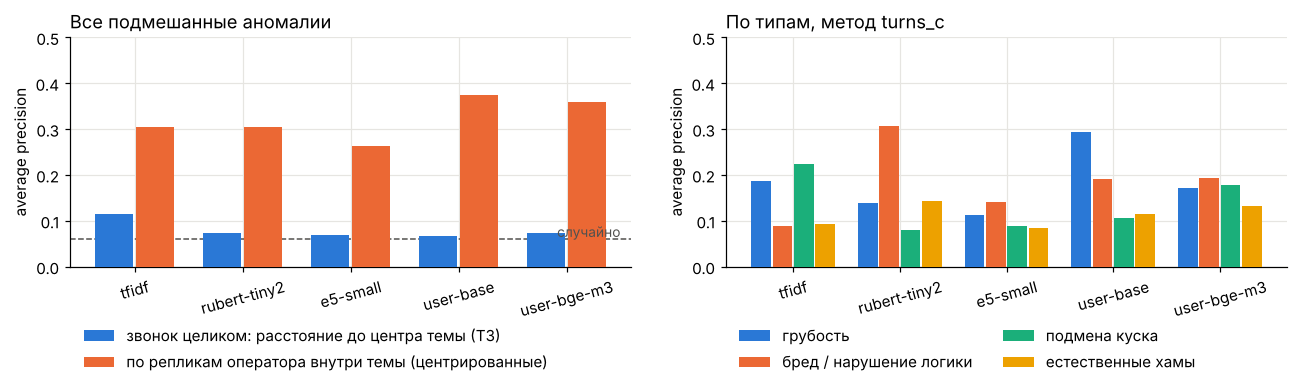

In [4]:
order = [m for m in ["tfidf", "rubert-tiny2", "e5-small", "user-base", "user-bge-m3"] if m in set(cm.model)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
t = cm[cm.method.isin(["centroid", "turns_c"])].pivot(index="model", columns="method", values="ap").reindex(order)
w = 0.38
for j, (meth, col, lab) in enumerate((("centroid", "#2a78d6", "звонок целиком: расстояние до центра темы (ТЗ)"), ("turns_c", "#eb6834", "по репликам оператора внутри темы (центрированные)"))):
    axes[0].bar(np.arange(len(order)) + (j - 0.5) * w, t[meth].values, width=w * 0.92, color=col, label=lab, zorder=3)
axes[0].axhline(0.06, color="#52514e", lw=1, ls="--"); axes[0].text(len(order) - 0.5, 0.065, "случайно", ha="right", fontsize=9, color="#52514e")
axes[0].set_xticks(np.arange(len(order)), order, rotation=15); axes[0].set_ylim(0, 0.5); axes[0].set_ylabel("average precision")
axes[0].set_title("Все подмешанные аномалии", loc="left"); axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.2))
b = cm[cm.method == "turns_c"].set_index("model").reindex(order)
types = [("ap_rude", "грубость", "#2a78d6"), ("ap_absurd", "бред / нарушение логики", "#eb6834"), ("ap_splice", "подмена куска", "#1baf7a"), ("ap_natural", "естественные хамы", "#eda100")]
w = 0.8 / len(types)
for j, (c, lab, col) in enumerate(types):
    axes[1].bar(np.arange(len(order)) + (j - 1.5) * w, b[c].values, width=w * 0.92, color=col, label=lab, zorder=3)
axes[1].set_xticks(np.arange(len(order)), order, rotation=15); axes[1].set_ylim(0, 0.5); axes[1].set_ylabel("average precision")
axes[1].set_title("По типам, метод turns_c", loc="left"); axes[1].legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.2))
plt.tight_layout(); plt.show()

## 3. Почему звонок целиком не работает, и нужны ли темы
Дополнительные проверки (`research/calls/extra.py`): сходство подменённого звонка с его же исходной версией против сходства
двух обычных звонков одной темы; оценка по репликам внутри темы против всего корпуса без тем; центрирование эмбеддингов.

In [5]:
p1, p2 = RES / "calls_splice_sanity.csv", RES / "calls_extra.csv"
if p1.exists():
    display(pd.read_csv(p1))
if p2.exists():
    ex = pd.read_csv(p2)
    display(ex[["model", "mean_pair_cos", "check", "ap", "auc", "p@120", "noise@120", "ap_splice", "ap_rude", "ap_absurd", "ap_natural"]].round(3))

,model,cos_spliced_vs_own_original_median,cos_two_normal_same_topic_median,cos_two_normal_same_topic_p10
0,rubert-tiny2,0.960,0.907,0.864
1,e5-small,0.965,0.922,0.900
2,user-base,0.910,0.687,0.567


,model,mean_pair_cos,check,ap,auc,p@120,noise@120,ap_splice,ap_rude,ap_absurd,ap_natural
0,e5-small,0.897,"turns в теме (k=10, 1 реплика)",0.158,0.753,0.217,0.092,0.046,0.076,0.048,0.081
1,e5-small,0.897,turns без тем,0.070,0.566,0.083,0.108,0.014,0.030,0.029,0.051
2,e5-small,0.897,"turns в теме, k=3",0.157,0.748,0.233,0.100,0.045,0.068,0.053,0.081
3,e5-small,0.897,"turns в теме, k=30",0.149,0.740,0.200,0.083,0.044,0.074,0.042,0.077
4,e5-small,0.897,"turns в теме, 2 реплики",0.131,0.714,0.158,0.117,0.054,0.057,0.032,0.107
5,e5-small,0.897,"turns в теме, все реплики",0.091,0.633,0.092,0.133,0.038,0.027,0.025,0.037
6,e5-small,0.897,knn звонка в теме,0.074,0.551,0.083,0.117,0.034,0.027,0.020,0.046
7,e5-small,0.897,knn звонка без тем,0.068,0.534,0.083,0.117,0.026,0.022,0.019,0.047
8,e5-small,0.897,центрирование: turns в теме,0.284,0.827,0.308,0.075,0.095,0.145,0.179,0.088
9,e5-small,0.897,центрирование: knn звонка,0.100,0.619,0.150,0.083,0.070,0.025,0.023,0.074


## 4. Порог и топ-N для контроля качества
В день ~3000 звонков. Практичный режим — ежедневный топ-N самых подозрительных на ручную проверку контролёру. Ниже —
точность и полнота на наших данных (доля аномалий 6%) и пересчёт точности на реалистичную долю аномалий (1% и 0.5%)
при тех же долях срабатываний на аномальных и нормальных звонках.

In [6]:
bm = cm[cm.method == "turns_c"].sort_values("auc", ascending=False).iloc[0]
p = ROOT / "build" / "research" / f"calls_scores__stt__{bm['model']}.parquet"
p = p if p.exists() else RES / f"calls_scores_{bm['model']}.parquet"          # копия в git: ноутбук перезапускается из чистого клона
sc = pd.read_parquet(p).merge(calls[["id", "kind", "anomaly_type"]], on="id")
pool = sc.kind != "natural"
s = sc.loc[pool, "turns_c"].to_numpy(); an = (sc.kind[pool] == "anomaly").to_numpy(); co = (sc.kind[pool] == "corrupted").to_numpy()
rows = []
for thr in (1.5, 2, 2.5, 3):
    f = s >= thr
    tpr, fpr = (s[an] >= thr).mean(), (s[~an] >= thr).mean()
    row = {"порог z": thr, "помечено, %": 100 * f.mean(), "точность": an[f].mean() if f.any() else 0, "полнота": tpr, "шум среди помеченных": co[f].mean() if f.any() else 0}
    for prev in (0.01, 0.005):
        row[f"точность при доле {prev:.1%}"] = prev * tpr / (prev * tpr + (1 - prev) * fpr) if tpr + fpr else 0
        row[f"помечено в день из 3000 при {prev:.1%}"] = round(3000 * (prev * tpr + (1 - prev) * fpr))
    rows.append(row)
print(f"конфигурация: {bm['model']} / turns_c (центрированные реплики оператора внутри темы)")
display(pd.DataFrame(rows).round(3))
o = np.argsort(-s)
pd.DataFrame([{"топ-N": n, "настоящих аномалий": int(an[o[:n]].sum()), "точность": an[o[:n]].mean(), "испорченных (шум)": int(co[o[:n]].sum())} for n in (20, 40, 60, 100, 150)]).round(2)

конфигурация: user-base / turns_c (центрированные реплики оператора внутри темы)


,порог z,"помечено, %",точность,полнота,шум среди помеченных,точность при доле 1.0%,помечено в день из 3000 при 1.0%,точность при доле 0.5%,помечено в день из 3000 при 0.5%
0,1.5,7.417,0.430,0.533,0.066,0.107,149,0.056,142
1,2.0,3.536,0.542,0.320,0.028,0.158,61,0.085,56
2,2.5,1.424,0.448,0.107,0.034,0.114,28,0.060,27
3,3.0,0.639,0.462,0.049,0.000,0.120,12,0.063,12


,топ-N,настоящих аномалий,точность,испорченных (шум)
0,20,9,0.45,1
1,40,21,0.52,1
2,60,29,0.48,2
3,100,48,0.48,5
4,150,65,0.43,10


In [7]:
top = sc.assign(score=sc["turns_c"]).sort_values("score", ascending=False).head(15).merge(calls[["id", "theme", "turns"]], on="id")
for _, r in top.iterrows():
    print(f"[z={r['score']:.1f}] {r['kind']:9} {r['anomaly_type'] or '':11} | {r['theme']}")

[z=4.4] anomaly   rude        | Продажа VPS-хостинга
[z=4.3] normal                | Попытка продажи услуги кофе-брейка и обработка отказа
[z=4.3] anomaly   rude        | Перенос доставки и корректировка заказа
[z=4.1] normal                | Перенос даты мероприятия и изменение заказа кейтеринга
[z=3.9] normal                | Жалоба клиента на испорченный банкет и требование возврата денег
[z=3.5] anomaly   rude        | Обсуждение условий сотрудничества по разработке backend для мобильного приложения
[z=3.4] anomaly   splice      | Проблема с входом в личный кабинет и доступом к расписанию фитнес-клуба
[z=3.2] normal                | Консультация по переходу на облачное хранилище
[z=3.2] anomaly   rude        | Обсуждение маркетинговых услуг для повышения конверсии сайта
[z=3.2] normal                | Организация кейтеринга для семинара с учётом диетических ограничений
[z=3.1] anomaly   absurd      | Отмена пробного периода IT-аутсорсинга
[z=3.1] normal                | Консультаци

## 5. Проверка выводов (аудит)
**5.1. Доверительные интервалы** (`research/calls/bootstrap.py`, бутстреп по звонкам, 1000 повторов, 95%):

In [8]:
p = RES / "calls_bootstrap.csv"
if p.exists():
    bs = pd.read_csv(p)
    bs["значение [95% ДИ]"] = bs.apply(lambda r: f"{r.value:.2f} [{r.ci_low:.2f}–{r.ci_high:.2f}]", axis=1)
    display(bs.pivot_table(index=["model", "method"], columns="metric", values="значение [95% ДИ]", aggfunc="first")
            [["ap", "auc", "p@40", "p@120", "precision_z2", "recall_z2", "flagged"]])

metric                              ap               auc              p@40             p@120      precision_z2         recall_z2           flagged
model       method                                                                                                                                
tfidf       centroid  0.12 [0.09–0.16]  0.66 [0.61–0.71]  0.10 [0.03–0.23]  0.14 [0.08–0.21]  0.14 [0.08–0.20]  0.14 [0.08–0.20]  0.06 [0.05–0.07]
            turns_c   0.31 [0.23–0.40]  0.80 [0.75–0.85]  0.55 [0.35–0.72]  0.32 [0.25–0.42]  0.39 [0.29–0.51]  0.25 [0.17–0.32]  0.04 [0.03–0.05]
user-base   centroid  0.07 [0.05–0.09]  0.54 [0.48–0.59]  0.05 [0.00–0.12]  0.07 [0.03–0.11]  0.08 [0.04–0.12]  0.11 [0.06–0.16]  0.08 [0.07–0.10]
            turns_c   0.37 [0.30–0.47]  0.86 [0.82–0.90]  0.53 [0.35–0.68]  0.47 [0.38–0.56]  0.54 [0.42–0.66]  0.32 [0.24–0.40]  0.04 [0.03–0.04]
user-bge-m3 centroid  0.07 [0.06–0.10]  0.56 [0.50–0.61]  0.05 [0.00–0.15]  0.09 [0.04–0.14]  0.09 [0.05–0.14]  0.12 [0.07–0.19]  0.08 [0.07–0.09]
            turns_c   0.36 [0.29–0.46]  0.86 [0.81–0.89]  0.55 [0.38–0.68]  0.42 [0.33–0.51]  0.48 [0.36–0.61]  0.24 [0.16–0.32]  0.03 [0.02–0.04]

**5.2. Ручной разбор топ-40** (ТЗ: «как проверить, что аномалия является таковой — вручную»). 40 самых подозрительных
звонков прочитаны вслепую, без разметки (читал разработчик): «аномалия» — хамство, абсурд, чужой кусок диалога;
«пограничный» — звонок из исходного датасета, который контролёру стоит посмотреть (некомпетентность, скрытые доплаты,
нарушение безопасности); потом сверено с разметкой.

In [9]:
p = RES / "calls_top40_manual.csv"
if p.exists():
    mt = pd.read_csv(p)
    display(pd.crosstab(mt["blind"], mt["kind"], margins=True))
    display(mt[mt.blind == "пограничный"][["rank", "id", "note", "politeness", "regulation"]])

kind,anomaly,corrupted,normal,All
blind,,,,
аномалия,21,0,0,21
норма,0,0,10,10
пограничный,0,0,8,8
шум STT,0,1,0,1
All,21,1,18,40


,rank,id,note,politeness,regulation
1,2,call-01163,после отказа продолжает продавать,7.0,6.0
3,4,call-01370,"фамильярность, доплата задним числом",6.0,5.0
4,5,call-01929,"смайлики и «упс, бывает» на жалобу о сорванном банкете",6.0,4.0
11,12,call-01241,оператор не знает продукт,7.0,4.0
19,20,call-01542,"череда ошибок, «звоните напрямую мне»",10.0,9.0
20,21,call-00502,оператор не знает сроков и цен,7.0,5.0
32,33,call-00197,принимает логин и пароль в переписке,7.0,9.0
39,40,call-01264,«документы подгоняем под тендер»,6.0,7.0


**5.3. Находит ли оценка естественно слабые звонки.** Среди нетронутых звонков — связь z с оценками работы оператора
из разметки самого датасета (0–10): AUC «оценка ≤ 6», ранговая корреляция, доля слабых в топ-40 и топ-100 нормальных
звонков против доли во всех нормальных.

In [10]:
p = RES / "calls_grades.csv"
pd.read_csv(p) if p.exists() else "нет данных"

,grade,low_share,auc_turns_c,auc_centroid,spearman_turns_c,low_share_top40,low_share_top100
0,politeness,0.128,0.591,0.565,-0.202,0.300,0.25
1,regulation,0.142,0.575,0.500,-0.189,0.275,0.28
2,efficiency,0.255,0.569,0.517,-0.146,0.300,0.35
3,result,0.295,0.580,0.529,-0.133,0.400,0.43
4,empathy,0.461,0.597,0.528,-0.173,0.700,0.67
5,literacy,0.044,0.659,0.602,-0.125,0.125,0.09
6,естественно невежливые (≤ 2) против нормальных,0.028,0.857,0.674,NaN,NaN,NaN


**5.4. Вне выборки: Russian MultiWOZ** (`research/calls/multiwoz_check.py`). Другой корпус (письменные диалоги о
бронировании гостиниц, ресторанов, поездов, такси), 3000 диалогов — дневной объём заказчика. Порча и аномалии теми же
функциями и в тех же долях; `splice` — кусок банковского диалога посреди диалога о бронировании (пример из ТЗ).
Скрипт `research/run_calls.py` запущен как есть: модель, метод и порог выбраны на основном корпусе, здесь ничего не
подбиралось.

In [11]:
p = RES / "mwoz_metrics.csv"
pd.read_csv(p) if p.exists() else "нет данных"

,subset,n_pos,base_rate,ap,auc,p@40,r@40,noise@40,p@80,r@80,...,noise@120,p@200,r@200,noise@200,flagged_share,precision,recall,noise_flagged,nmi,n_topics
0,все аномалии,180.0,0.0600,0.5666,0.9477,0.625,0.1389,0.05,0.7,0.3111,...,0.0333,0.575,0.6389,0.06,NaN,NaN,NaN,NaN,NaN,NaN
1,rude,54.0,0.0188,0.3298,0.9735,0.400,0.2963,0.05,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,absurd,54.0,0.0188,0.4242,0.9773,0.475,0.3519,0.05,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,splice,45.0,0.0157,0.2410,0.9618,0.325,0.2889,0.10,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,splice_near,27.0,0.0095,0.0752,0.8136,0.125,0.1852,0.10,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,порог z ≥ 2,180.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0613,0.5924,0.6056,0.0489,NaN,NaN
6,темы против областей,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6963,23.0


**5.5. Подмена куска разговора — отдельный сигнал.** Подмену основная оценка ловит хуже всего. Проверены две добавки:
новизна реплик **клиента** (в подмешанном куске чужие и они) и «**чужая тема по репликам**» (`lurker.anomaly.offtopic_score`:
реплика ближе к центру другой темы, чем к своей). Обе ловят подмену лучше основной оценки, но, смешанные с ней, теряют на
грубости и бреде — поэтому их стоит вести отдельным списком, а не одной оценкой.

In [12]:
cols = ["model", "method", "ap", "auc", "p@40", "p@120", "noise@120", "ap_splice", "ap_splice_near", "ap_rude", "ap_absurd"]
cm[(cm.variant == "stt") & cm.model.isin(["user-base", "tfidf"]) & cm.method.isin(["turns_c", "client_c", "offtopic", "op+client_m1", "op+offtopic"])][cols].round(3)

,model,method,ap,auc,p@40,p@120,noise@120,ap_splice,ap_splice_near,ap_rude,ap_absurd
42,user-base,turns_c,0.374,0.861,0.525,0.467,0.042,0.107,0.030,0.294,0.192
43,user-base,client_c,0.123,0.581,0.275,0.158,0.142,0.188,0.026,0.022,0.017
44,user-base,offtopic,0.166,0.680,0.225,0.225,0.042,0.238,0.024,0.032,0.027
46,user-base,op+client_m1,0.373,0.866,0.525,0.458,0.042,0.109,0.030,0.292,0.189
47,user-base,op+offtopic,0.340,0.869,0.400,0.408,0.033,0.201,0.025,0.195,0.130
59,tfidf,turns_c,0.305,0.801,0.550,0.317,0.050,0.223,0.032,0.187,0.089
60,tfidf,client_c,0.078,0.556,0.125,0.092,0.100,0.060,0.012,0.021,0.017
61,tfidf,offtopic,0.184,0.679,0.375,0.242,0.075,0.193,0.100,0.033,0.030
63,tfidf,op+client_m1,0.298,0.798,0.550,0.308,0.050,0.220,0.031,0.186,0.084
64,tfidf,op+offtopic,0.301,0.814,0.550,0.342,0.067,0.198,0.092,0.152,0.083


## Выводы по задаче 2

**Гипотеза подтверждается частично.** Эмбеддинги находят звонки, где оператор сказал что-то чуждое теме (грубость, бред,
нарушение бизнес-логики), но только если сравнивать **отдельные реплики оператора внутри темы**, а не звонок целиком.
Схема из ТЗ в лоб (эмбеддинг всего звонка → расстояние до центра темы) на этих данных не работает. Вывод проверен вне
выборки — на другом корпусе, где ничего не подбиралось, — и там метод работает не хуже.

1. **Звонок целиком: не работает.** Расстояние до центра темы, kNN и LOF по эмбеддингу всего звонка дают AP 0.07–0.14
   при случайном уровне 0.06 — у всех пяти моделей (у USER-base AP 0.07, 95% ДИ 0.05–0.09). Причина измерена
   (`calls_splice_sanity.csv`): локальная аномалия растворяется при усреднении всего диалога в один вектор. Звонок, у
   которого 40% реплик заменены куском из другой области, остаётся ближе к своей исходной версии (сходство 0.96 у
   rubert-tiny2, 0.91 у USER-base), чем два обычных звонка одной темы друг к другу (0.91 и 0.69).
2. **По репликам внутри темы: работает.** Каждая реплика оператора сравнивается с 10 ближайшими репликами операторов в
   других звонках той же темы, звонок оценивается по самой непохожей реплике. Лучшая конфигурация — **USER-base** на
   центрированных эмбеддингах реплик: **AP 0.37 (95% ДИ 0.30–0.47)** — в 6 раз выше случайного, AUC 0.86 (0.82–0.90);
   в топ-40 — 53% настоящих аномалий (35–68%), в топ-120 — 47%. По типам: грубость AP 0.29, бред и нарушение логики
   0.19, подмена куска диалога 0.11 (из близкой области — 0.03; лучше всех на подмене TF-IDF по репликам, 0.22). USER-bge-m3 статистически неотличим (AP 0.36, ДИ 0.29–0.46), TF-IDF по
   репликам немного хуже (0.31, ДИ 0.23–0.40); USER-base выбран за скорость.
3. **Вне выборки (Russian MultiWOZ, 3000 диалогов — дневной объём).** Те же доли порчи и аномалий, `research/run_calls.py`
   как есть: **AP 0.57, AUC 0.95, в топ-40 — 63% аномалий**; порог z ≥ 2 помечает 6.1% звонков с точностью 0.59 и
   полнотой 0.61. Кусок банковского диалога в диалоге о бронировании (пример из ТЗ) — AP 0.24 при случайном 0.016;
   кусок соседней области (гостиница ↔ ресторан) — по-прежнему слабо (0.08). Темы совпадают с областями: NMI 0.70.
4. **Ручная проверка топ-40** (вслепую, потом сверка с разметкой): все 21 подмешанная аномалия и 1 испорченный звонок
   распознаны глазами так же, как в разметке; из 18 «нормальных» звонков топа **8 — действительно спорные** звонки из
   исходного датасета: некомпетентный оператор, доплата задним числом, «документы подгоняем под тендер», логин и пароль
   в переписке. То есть контролёру стоило бы посмотреть 29 из 40 (72%), а не 21 (53%, как по разметке). На MultiWOZ
   «ложные тревоги» топа тоже часто реальные странности: ошибки машинного перевода и ответы невпопад.
5. **Естественно слабые звонки метод тоже поднимает, хотя и слабее.** Среди нетронутых звонков оценка связана с оценками
   работы оператора из разметки самого датасета: AUC 0.57–0.66 по шести критериям; среди 40 самых подозрительных
   «нормальных» звонков низкая оценка за регламент встречается вдвое чаще, чем в среднем (28% против 14%). Естественно
   невежливых операторов (вежливость ≤ 2) метод отделяет от нормальных с AUC 0.86 — так же, как подмешанную грубость;
   AP у них 0.11 только потому, что их 2.6%.
6. **Темы нужны, как и предполагает ТЗ.** Та же оценка по репликам без разбиения на темы даёт AP 0.07–0.16 вместо
   0.27–0.37: «нормальность» реплики зависит от темы звонка.
7. **Шум распознавания речи почти не даёт ложных тревог.** Среди 120 самых подозрительных звонков испорченных 4%
   (на MultiWOZ — 3%) при их доле 8% в данных: опечатки и слипшиеся слова не делают реплику «чужой» по смыслу.
8. **Подмена куска разговора — отдельный сигнал, а не добавка к основному.** Основная оценка ловит подмену хуже всего
   (AP 0.11). Проверены две добавки: новизна реплик **клиента** (в подмешанном куске чужие и они) — подмена AP 0.19 — и
   «**чужая тема по репликам**» (`lurker.anomaly.offtopic_score`: реплика ближе к центру другой темы, чем к своей) —
   AP 0.24. Но смешанные с основной оценкой в одну они проигрывают на грубости и бреде (AP всех аномалий 0.34–0.37 против
   0.37): клиенты говорят свободнее операторов, и их «чужие» реплики шумят. Подмену из близкой темы не ловит ничего
   (AP 0.03; лучшее — TF-IDF «чужая тема», 0.10). Практично вести **второй, отдельный список** («чужой кусок разговора»)
   рядом с основным.

**Рекомендация.** Модель — USER-base; оценка — новизна центрированных реплик оператора внутри темы
(`research/run_calls.py`); режим — **ежедневный топ-N на ручную проверку**, а не автоматическое наказание. Порог z ≥ 2
на основном корпусе помечает 3.5% звонков (точность 0.54, ДИ 0.42–0.66; полнота 0.32), на MultiWOZ — 6.1%: доля
помеченных зависит от потока, поэтому на реальных данных порог лучше выбирать под объём, который контролёры успевают
проверить (например, топ-50 в день), и пересматривать по первым неделям разметки. При доле аномалий около 1% из 3000
звонков в день порог z ≥ 2 даст около 60, проблемным будет примерно каждый шестой — в 16 раз лучше случайной выборки,
не считая «спорных» звонков, которые тоже стоит посмотреть.

**Ограничения.** Аномалии искусственные (одна вставленная фраза, подмена куска), диалоги — письменные (сгенерированные LLM
и переведённые), приведены к виду STT. На реальных расшифровках (длиннее, с перебивами и ошибками распознавания) цифры
нужно перемерить; ближайший к реальности ориентир — естественно слабые звонки из п. 5. Смысловые аномалии, которые не
выражаются одной репликой (оператор не сделал нужного действия, нарушил порядок шагов), этим методом не видны. Объём
3000 звонков проверен на MultiWOZ; основной корпус меньше (2087) — перефразировать диалоги до 3000, как допускает ТЗ,
мы сознательно не стали: перефразы одного диалога стали бы «близнецами» и искусственно облегчили бы поиск соседей.
Банковские диалоги, которые упоминает ТЗ (kolestv108/Russian-Banking-Dialogues-Dataset), третьим корпусом не взяли:
в первых 100 строках файла — 4 шаблонные пары «вопрос — ответ» из двух реплик, повторённые по кругу, искать аномалии
внутри темы там не на чем.